# 07 · Final model, saving and prediction on a new recording

The last steps of a standard ML pipeline:
1. **Honest check of the final recipe:** train the pooled model WITHOUT some speakers and test on them
2. **Train the final models on all data** (RAVDESS + CREMA-D, every labelled clip)
3. **Save them** to `models/final_models.joblib` (git-ignored, never pushed)
4. **Predict a new audio file** and explain the prediction with SHAP

Two models are saved:
| Role | Model | Why |
|---|---|---|
| predictor | LogReg on **fusion** (eGeMAPS + WavLM layer) | best UAR in Phases 6 and 8 |
| explainer | LogReg on **eGeMAPS** | named voice features, exact linear SHAP (Phase 7) |

Run time on a MacBook: about 3–6 minutes (needs the cached features in `data/processed/`).

In [1]:
import sys, json
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report
from src.models import load_corpus, CLASSES, fit_tuned, select_layer
from src.predict import train_final, save_final, load_final, predict_features, predict_file, pooled_training_data, BUNDLE_PATH

FIG_DIR = PROJECT_ROOT / "results" / "figures"
OUT = PROJECT_ROOT / "results" / "phase9"; OUT.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GREY, MUTED = "#2a78d6", "#eb6834", "#b8b6ad", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.edgecolor": MUTED, "figure.dpi": 110})
corpora = {c: load_corpus(c) for c in ["ravdess", "cremad"]}
print({c: (len(d["y"]), len(np.unique(d["groups"]))) for c, d in corpora.items()})

{'ravdess': (1056, 24), 'cremad': (7442, 91)}


## 1. Honest check: pooled model on speakers it has never heard
The final model is trained on everything, so it cannot be tested afterwards. Instead we test the **same recipe** (layer choice + tuning on training speakers only) with **fold 0 of both corpora held out** (≈20% of speakers).

In [2]:
ARRAYS = ["y", "groups", "folds", "egemaps", "wavlm"]
def subset(d, mask):
    out = {k: np.asarray(d[k])[mask] for k in ARRAYS}
    out["egemaps_names"] = d["egemaps_names"]
    return out

train = {c: subset(d, d["folds"] != 0) for c, d in corpora.items()}
test = {c: subset(d, d["folds"] == 0) for c, d in corpora.items()}
check = train_final(train)
rows = []
for c in test:
    X = np.hstack([test[c]["egemaps"], test[c]["wavlm"][:, check["layer"]]])
    pred = check["predictor"].predict(X)
    pred_e = check["explainer"].predict(test[c]["egemaps"])
    for name, p in [("predictor (fusion)", pred), ("explainer (eGeMAPS)", pred_e)]:
        rows.append({"test corpus": c, "model": name, "n_speakers": len(np.unique(test[c]["groups"])),
                     "UAR": balanced_accuracy_score(test[c]["y"], p), "macro_F1": f1_score(test[c]["y"], p, average="macro")})
heldout = pd.DataFrame(rows)
# reference: the single-corpus Phase 6 model on the SAME held-out fold
P6 = PROJECT_ROOT / "results" / "phase6"
ref = {(c, fs): pd.read_csv(P6 / f"e1_{c}_{fs}_logreg.csv").set_index("fold").loc[0, "uar"]
       for c in corpora for fs in ["fusion", "egemaps"]}
heldout["Phase6_single_corpus_UAR"] = [ref[(r["test corpus"], "fusion" if "fusion" in r["model"] else "egemaps")]
                                       for _, r in heldout.iterrows()]
heldout.to_csv(OUT / "final_recipe_heldout.csv", index=False)
print("layer chosen:", check["layer"], "| params:", check["info"]["predictor_params"])
heldout.round(3)

layer chosen: 6 | params: {'clf__C': 0.01}


,test corpus,model,n_speakers,UAR,macro_F1,Phase6_single_corpus_UAR
0,ravdess,predictor (fusion),5,0.725,0.731,0.750
1,ravdess,explainer (eGeMAPS),5,0.471,0.476,0.512
2,cremad,predictor (fusion),18,0.723,0.714,0.715
3,cremad,explainer (eGeMAPS),18,0.489,0.479,0.505


The last column is the Phase 6 model trained on **one** corpus, tested on the same fold-0 speakers. In our sandbox test, pooling cost about 2–4 points on RAVDESS (it is outnumbered 7 : 1 by CREMA-D clips) and changed CREMA-D by under 2 points, in exchange for one model that has heard both recording styles (Phase 8 showed single-corpus models break on the other corpus). Fold 0 holds only 5 RAVDESS speakers, so these differences are rough.

## 2. Train the final models on ALL labelled clips and save them

In [3]:
bundle = train_final(corpora)
path = save_final(bundle)
print("saved to", path.relative_to(PROJECT_ROOT), f"({path.stat().st_size/1e6:.1f} MB)")
print(json.dumps(bundle["info"], indent=2, default=str))

saved to models/final_models.joblib (0.1 MB)
{
  "trained_on": "RAVDESS + CREMA-D (all labelled clips)",
  "n_clips": 8498,
  "n_speakers": 115,
  "predictor_params": {
    "clf__C": 0.01
  },
  "explainer_params": {
    "clf__C": 1.0
  },
  "layer_profile_inner_uar": [
    0.5924,
    0.6195,
    0.6438,
    0.6698,
    0.6935,
    0.7177,
    0.7208,
    0.7258,
    0.715,
    0.7069,
    0.706,
    0.697,
    0.6921
  ],
  "wavlm_model": "microsoft/wavlm-base-plus",
  "sample_rate": 16000,
  "sklearn": "1.9.1",
  "python": "3.11.17",
  "date": "2026-10-19"
}


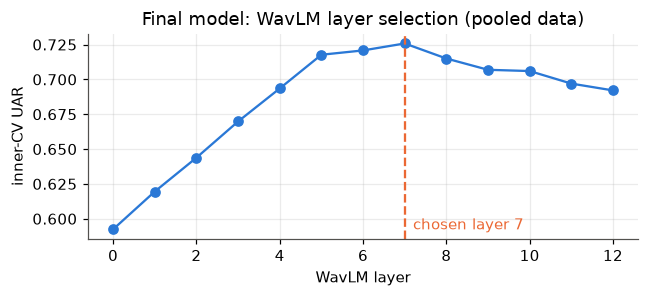

In [4]:
prof = bundle["info"]["layer_profile_inner_uar"]
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(range(len(prof)), prof, "-o", color=BLUE)
ax.axvline(bundle["layer"], color=ORANGE, ls="--")
ax.text(bundle["layer"] + 0.2, min(prof), f"chosen layer {bundle['layer']}", color=ORANGE)
ax.set_xlabel("WavLM layer"); ax.set_ylabel("inner-CV UAR"); ax.set_title("Final model: WavLM layer selection (pooled data)")
fig.tight_layout(); fig.savefig(FIG_DIR / "p9_final_layer.png", dpi=150); plt.show()

## 3. Reload from disk (proves the saved file works on its own)

In [5]:
bundle = load_final()
d = corpora["cremad"]; i = 0
r = predict_features(d["egemaps"][i], d["wavlm"][i], bundle)
print("file:", d["meta"]["file"][i], "| true:", CLASSES[d["y"][i]], "| predicted:", r["label"])
print("NOTE: this clip was in the training data; this only checks that loading and predicting work.")

file: 1001_DFA_ANG_XX.wav | true: angry | predicted: angry
NOTE: this clip was in the training data; this only checks that loading and predicting work.


## 4. Predict a NEW recording (end-to-end: audio → features → emotion → explanation)
`predict_file()` runs exactly the Phase 5 pipeline (mono, 16 kHz, trim silence) then eGeMAPS + WavLM, then both models.

**Try your own voice:** record a 2–4 s sentence with QuickTime (File → New Audio Recording), export, convert to `.wav` (e.g. `ffmpeg -i my.m4a my_voice.wav`) and put it in the project folder as `my_voice.wav`. Your own recordings are **not** in the training data, so they are a genuine new test, but also a different microphone and speaker style, so expect lower accuracy (Phase 8 showed how much a change of recording conditions costs).

In [6]:
own = PROJECT_ROOT / "my_voice.wav"
demo_path = own if own.exists() else PROJECT_ROOT / corpora["ravdess"]["meta"]["path"][100]
print("predicting:", demo_path.name, "(your own recording)" if own.exists() else "(RAVDESS clip, seen in training: demo only)")
result = predict_file(demo_path, bundle)
print(f"\nPredicted emotion: {result['label'].upper()}  (duration {result['duration_s']} s)")
print("Interpretable eGeMAPS model says:", result["explainer_label"])
for w in result["warnings"]:
    print("WARNING:", w)
pd.Series(result["proba"]).sort_values(ascending=False).round(3)

predicting: 03-01-04-01-01-01-03.wav (RAVDESS clip, seen in training: demo only)


W1019 20:16:05.223000 72863 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]


Predicted emotion: SAD  (duration 1.89 s)
Interpretable eGeMAPS model says: neutral


sad        0.523
fearful    0.238
disgust    0.134
happy      0.082
neutral    0.017
angry      0.007
dtype: float32

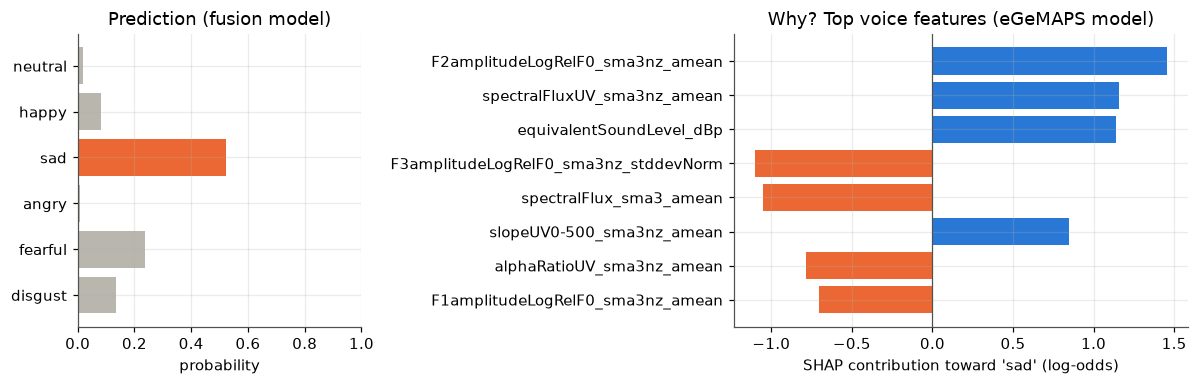

,feature,group,value,contribution,direction
0,F2amplitudeLogRelF0_sma3nz_amean,Spectral,-96.183998,1.458,toward
1,spectralFluxUV_sma3nz_amean,Spectral,0.012000,1.157,toward
2,equivalentSoundLevel_dBp,Energy,-45.200001,1.137,toward
3,F3amplitudeLogRelF0_sma3nz_stddevNorm,Spectral,-0.825000,-1.104,away from
4,spectralFlux_sma3_amean,Spectral,0.024000,-1.051,away from
5,slopeUV0-500_sma3nz_amean,Spectral,0.050000,0.846,toward
6,alphaRatioUV_sma3nz_amean,Spectral,-10.096000,-0.787,away from
7,F1amplitudeLogRelF0_sma3nz_amean,Spectral,-92.781998,-0.702,away from


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
p = pd.Series(result["proba"]).reindex(CLASSES)
axes[0].barh(CLASSES, p.values, color=[ORANGE if c == result["label"] else GREY for c in CLASSES])
axes[0].invert_yaxis(); axes[0].set_xlim(0, 1); axes[0].set_xlabel("probability")
axes[0].set_title("Prediction (fusion model)")
ex = result["explanation"].iloc[::-1]
axes[1].barh(ex["feature"], ex["contribution"], color=[BLUE if v > 0 else ORANGE for v in ex["contribution"]])
axes[1].axvline(0, color=MUTED, lw=0.8)
axes[1].set_xlabel(f"SHAP contribution toward '{result['label']}' (log-odds)")
axes[1].set_title("Why? Top voice features (eGeMAPS model)")
fig.tight_layout(); fig.savefig(FIG_DIR / "p9_predict_demo.png", dpi=150); plt.show()
result["explanation"].round(3)

**How to read this:** blue bars push the prediction **toward** the emotion, orange bars push **away**. Values are exact linear SHAP of the eGeMAPS model (Phase 7), relative to the average training clip.

**Honest caveats shown to every user (Phase 9 app will display the same):**
- Probabilities come from logistic regression; Phase 8 (E6) measured their calibration (ECE), so treat them as rough scores, not certainties.
- Acted speech only; real, spontaneous emotion is subtler.
- A different microphone or room shifts the features (Phase 8, E2); the app warns when many features fall outside the training range.

In [8]:
summary = {"heldout_check": heldout.round(4).to_dict(orient="records"), "final_info": bundle["info"],
           "demo_file": demo_path.name, "demo_prediction": result["label"], "demo_warnings": result["warnings"]}
(PROJECT_ROOT / "results" / "phase9_final_model_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("saved results/phase9_final_model_summary.json")

saved results/phase9_final_model_summary.json
